# Austin Animal Center EDA

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# data is split between two CSVs
intakes = pd.read_csv('data/aac_intakes.csv')
outcomes = pd.read_csv('data/aac_outcomes.csv')

In [3]:
intakes.head(5)

,Animal ID,Name,DateTime,MonthYear,Found Location,Intake Type,Intake Condition,Animal Type,Sex upon Intake,Age upon Intake,Breed,Color
0,A521520,Nina,10/01/2013 07:51:00 AM,October 2013,Norht Ec in Austin (TX),Stray,Normal,Dog,Spayed Female,7 years,Border Terrier/Border Collie,White/Tan
1,A664235,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
2,A664236,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
3,A664237,NaN,10/01/2013 08:33:00 AM,October 2013,Abia in Austin (TX),Stray,Normal,Cat,Unknown,1 week,Domestic Shorthair Mix,Orange/White
4,A664233,Stevie,10/01/2013 08:53:00 AM,October 2013,7405 Springtime in Austin (TX),Stray,Injured,Dog,Intact Female,3 years,Pit Bull Mix,Blue/White


In [4]:
outcomes.head(5)

,Animal ID,Date of Birth,Name,DateTime,MonthYear,Outcome Type,Outcome Subtype,Animal Type,Sex upon Outcome,Age upon Outcome,Breed,Color
0,A668305,2012-12-01,NaN,2013-12-02T00:00:00-05:00,12-2013,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Brown/Yellow
1,A673335,2012-02-22,NaN,2014-02-22T00:00:00-05:00,02-2014,Euthanasia,Suffering,Other,Unknown,2 years,Raccoon,Black/Gray
2,A675999,2013-04-03,NaN,2014-04-07T00:00:00-05:00,04-2014,Transfer,Partner,Other,Unknown,1 year,Turtle Mix,Green
3,A679066,2014-04-16,NaN,2014-05-16T00:00:00-05:00,05-2014,NaN,NaN,Other,Unknown,4 weeks,Rabbit Sh,Brown
4,A680855,2014-05-25,NaN,2014-06-10T00:00:00-05:00,06-2014,Transfer,Partner,Bird,Unknown,2 weeks,Duck,Yellow/Black


In [5]:
print(outcomes['DateTime'].str.len().value_counts())
tz_rows = outcomes[outcomes['DateTime'].str.len() > 19]
print(tz_rows['DateTime'].str[11:19].value_counts())


DateTime
19    170191
25      3584
Name: count, dtype: int64
DateTime
00:00:00    3584
Name: count, dtype: int64


In [6]:
# Clean up column names and mixed date formatting
intakes.columns = intakes.columns.str.replace(' ', '_').str.lower()
outcomes.columns = outcomes.columns.str.replace(' ', '_').str.lower()
intakes['intake_datetime'] = pd.to_datetime(intakes['datetime'])
# Outcome datetime has a timezone which doesnt add value, we can safely drop
outcomes['outcome_datetime'] = pd.to_datetime(
  outcomes['datetime'].str[:19], format='%Y-%m-%dT%H:%M:%S'
)


In [7]:
# Some animals have multiple intakes. We will focus on 
print(intakes.groupby('animal_id').size().sort_values())
print(intakes.loc[intakes.animal_id == 'A721033'])
print(outcomes.loc[outcomes.animal_id == 'A721033'])

# Public assist has to do with temporary housing. We can remove this from the analysis 
# merging intakes to outcomes will be hard. We need to match an outcome to its most recent prior intake

animal_id
A812743     1
A812730     1
A812732     1
A812733     1
A812734     1
           ..
A706536    11
A705625    12
A718877    12
A718223    14
A721033    33
Length: 156287, dtype: int64
       animal_id     name                datetime       monthyear  \
43498    A721033  Lil Bit  02/20/2016 10:44:00 AM   February 2016   
51001    A721033  Lil Bit  07/10/2016 11:53:00 AM       July 2016   
53835    A721033  Lil Bit  09/03/2016 02:30:00 PM  September 2016   
56121    A721033  Lil Bit  10/20/2016 10:47:00 PM    October 2016   
58575    A721033  Lil Bit  12/15/2016 10:07:00 AM   December 2016   
59568    A721033  Lil Bit  01/09/2017 02:26:00 PM    January 2017   
60211    A721033  Lil Bit  01/26/2017 06:55:00 AM    January 2017   
60407    A721033  Lil Bit  01/30/2017 11:05:00 PM    January 2017   
60647    A721033  Lil Bit  02/06/2017 10:13:00 AM   February 2017   
62261    A721033  Lil Bit  03/15/2017 09:24:00 AM      March 2017   
78680    A721033  Lil Bit  02/22/2018 10:28:00 A

In [8]:
# Duplicates exist
intakes.drop_duplicates(inplace = True)
outcomes.drop_duplicates(inplace = True)

/tmp/ipykernel_38387/1855205345.py:2: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  intakes.drop_duplicates(inplace = True)
/tmp/ipykernel_38387/1855205345.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  outcomes.drop_duplicates(inplace = True)


## Merging intakes with outcomes


In [9]:
# Date-only outcomes (the "-05:00" midnight rows): treat as end of that day,
# so an intake earlier the same day can still match them
date_only = outcomes['datetime'].str.len() > 19
outcomes['match_time'] = outcomes['outcome_datetime'].where(
    ~date_only, outcomes['outcome_datetime'] + pd.Timedelta(hours=23, minutes=59)
)

# For each intake, when does this animal come in next? (NaT if never)
intakes = intakes.sort_values('intake_datetime')
intakes['next_intake_datetime'] = (
    intakes.groupby('animal_id')['intake_datetime'].shift(-1)
)

# Match each intake to the first outcome at or after it, for the same animal
df = pd.merge_asof(
    intakes,
    outcomes.sort_values('match_time'),
    left_on='intake_datetime',
    right_on='match_time',
    by='animal_id',
    direction='forward',
    suffixes=('_intake', '_outcome'),
)
print(f'Intakes:                         {len(df):,}')
print(f'Intakes with no outcome found:   {df["match_time"].isna().sum():,}')

# Throw away matches that happen after the animal's next intake:
# that outcome belongs to the later stay, not this one
overlap = df['match_time'] >= df['next_intake_datetime']
print(f'Outcome belonged to a later stay: {overlap.sum():,}')

df = df[~overlap & df['outcome_type'].notna()].reset_index(drop=True)
print(f'Final stays with a target:        {len(df):,}')

Intakes:                         173,776
Intakes with no outcome found:   1,262
Outcome belonged to a later stay: 46
Final stays with a target:        172,425


In [10]:
# Sanity checks on the merge
# every outcome is on or after the day of its intake
assert (df['outcome_datetime'] >= df['intake_datetime'].dt.normalize()).all()
# no outcome was matched to more than one intake
assert not df.duplicated(['animal_id', 'match_time']).any()

# The animal with 33 intakes should now have one outcome per stay
df.loc[df['animal_id'] == 'A721033',
       ['intake_datetime', 'intake_type', 'outcome_datetime', 'outcome_type']]

,intake_datetime,intake_type,outcome_datetime,outcome_type
43421,2016-02-20 10:44:00,Stray,2016-02-20 16:18:00,Return to Owner
50914,2016-07-10 11:53:00,Stray,2016-07-11 17:44:00,Return to Owner
53747,2016-09-03 14:30:00,Public Assist,2016-09-12 13:40:00,Return to Owner
56031,2016-10-20 22:47:00,Public Assist,2016-10-21 18:55:00,Return to Owner
58481,2016-12-15 10:07:00,Public Assist,2016-12-16 11:32:00,Return to Owner
59474,2017-01-09 14:26:00,Stray,2017-01-10 16:20:00,Return to Owner
60116,2017-01-26 06:55:00,Public Assist,2017-01-28 15:22:00,Return to Owner
60312,2017-01-30 23:05:00,Public Assist,2017-02-02 11:19:00,Return to Owner
60552,2017-02-06 10:13:00,Public Assist,2017-02-07 17:26:00,Return to Owner
62163,2017-03-15 09:24:00,Public Assist,2017-03-16 12:50:00,Return to Owner


## Scope and target

We predict, **at intake**, whether a dog or cat will be adopted.

- Keep only dogs and cats
- Drop intakes that aren't adoption candidates: wildlife, public assist (temporary housing), and euthanasia requests
- Drop outcomes where we don't know what happened: missing, stolen, lost
- Target `adopted` = 1 for `Adoption`, 0 for everything else (transfer, return to owner, Rto-Adopt, euthanasia, died, ...)

Only `_intake` columns can be used as features. The `_outcome` versions (sex, age) are recorded when the animal leaves,
so they leak the answer: e.g. animals are spayed/neutered before adoption.

In [11]:
KEEP_ANIMALS = ['Dog', 'Cat']
DROP_INTAKES = ['Wildlife', 'Public Assist', 'Euthanasia Request']
DROP_OUTCOMES = ['Missing', 'Stolen', 'Lost']

df = (
    df
    .query('animal_type_intake in @KEEP_ANIMALS')
    .query('intake_type not in @DROP_INTAKES')
    .query('outcome_type not in @DROP_OUTCOMES')
    .assign(adopted=lambda d: (d['outcome_type'] == 'Adoption').astype(int))
    .reset_index(drop=True)
)

print(f'Stays in scope: {len(df):,}')
df['outcome_type'].value_counts()

Stays in scope: 152,517


outcome_type
Adoption           80806
Transfer           45669
Return to Owner    19150
Euthanasia          4212
Died                1347
Rto-Adopt           1092
Disposal             235
Relocate               6
Name: count, dtype: int64

In [12]:
df['adopted'].value_counts(normalize=True).round(3)

adopted
1    0.53
0    0.47
Name: proportion, dtype: float64

## Time-based split

The model would be used on animals arriving in the future, so we train on older stays and evaluate on the most recent ones:
60% train / 20% validation / 20% test, ordered by intake date.

We keep everything in one dataframe with a `split` column, so feature engineering is written once.
Anything that looks at the target (EDA on adoption rates, target encoding) should only use `split == 'train'`.

In [13]:
df = df.sort_values('intake_datetime').reset_index(drop=True)

n = len(df)
df['split'] = np.select(
    [df.index < 0.6 * n, df.index < 0.8 * n],
    ['train', 'val'],
    default='test',
)

df.groupby('split', sort=False).agg(
    first_intake=('intake_datetime', 'min'),
    last_intake=('intake_datetime', 'max'),
    stays=('adopted', 'size'),
    adoption_rate=('adopted', 'mean'),
).round({'adoption_rate': 3})

,first_intake,last_intake,stays,adoption_rate
split,,,,
train,2013-10-01 07:51:00,2019-07-10 14:32:00,91511,0.482
val,2019-07-10 14:53:00,2022-04-26 14:29:00,30503,0.563
test,2022-04-26 15:20:00,2025-05-04 13:15:00,30503,0.641


## Feature engineering

The breed column needs to be processed. Breed looks like free text but it appears to be coded vocabulary from a system with a few distinct formats.

In [14]:
df['breed_intake']

0          Border Terrier/Border Collie
1                Domestic Shorthair Mix
2                Domestic Shorthair Mix
3                Domestic Shorthair Mix
4                          Pit Bull Mix
                      ...              
152512               Domestic Shorthair
152513               Domestic Shorthair
152514           Domestic Shorthair Mix
152515    Chihuahua Shorthair/Dachshund
152516               American Shorthair
Name: breed_intake, Length: 152517, dtype: str

## Breed features

`breed` looks like free text, but it's a coded vocabulary from the shelter's system with three formats:

| Format | Example | Meaning |
|---|---|---|
| `<breed>` | `Beagle` | pure breed |
| `<breed> Mix` | `Beagle Mix` | looks mostly like this breed |
| `<breed>/<breed>` | `Beagle/Boxer` | cross of two named breeds |

There are ~2,600 distinct raw values, far too many to one-hot encode, and most are rare. Instead we parse the format:

1. **Clean**: `Black/Tan Hound` is one breed with a `/` in its name, so rename it before splitting. Also expand names the system truncated (`Chesa Bay Retr`).
2. **`breed_type`**: pure / mix / cross
3. **`primary_breed`** (first breed listed) and **`secondary_breed`** (second breed of a cross)
4. **`primary_breed_grouped`**: rare primary breeds collapsed into `Other Dog` / `Other Cat`, using **training-set counts only**

In [15]:
# Names the shelter system truncated -> full breed name
BREED_FIXES = {
    'Anatol Shepherd': 'Anatolian Shepherd',
    'Bedlington Terr': 'Bedlington Terrier',
    'Bouv Flandres': 'Bouvier Des Flandres',
    'Boykin Span': 'Boykin Spaniel',
    'Bruss Griffon': 'Brussels Griffon',
    'Cavalier Span': 'Cavalier King Charles Spaniel',
    'Chesa Bay Retr': 'Chesapeake Bay Retriever',
    'Dachshund Stan': 'Dachshund',
    'Doberman Pinsch': 'Doberman Pinscher',
    'Eng Toy Spaniel': 'English Toy Spaniel',
    'Oriental Sh': 'Oriental Shorthair',
    'Patterdale Terr': 'Patterdale Terrier',
    'Pbgv': 'Petit Basset Griffon Vendeen',
    'Port Water Dog': 'Portuguese Water Dog',
    'Rhod Ridgeback': 'Rhodesian Ridgeback',
    'Sealyham Terr': 'Sealyham Terrier',
    'Sussex Span': 'Sussex Spaniel',
    'Treeing Tennesse Brindle': 'Treeing Tennessee Brindle',
    'West Highland': 'West Highland White Terrier',
    'Yorkshire': 'Yorkshire Terrier',
}

In [16]:
# 'Black/Tan Hound' is a single breed; protect it before splitting on '/'
breed = df['breed_intake'].str.replace('Black/Tan Hound', 'Black and Tan Hound', regex=False)
breed_parts = breed.str.removesuffix(' Mix').str.split('/')

df = df.assign(
    breed_type=np.select(
        [breed.str.endswith(' Mix'), breed.str.contains('/')],
        ['mix', 'cross'],
        default='pure',
    ),
    primary_breed=breed_parts.str[0].replace(BREED_FIXES),
    secondary_breed=breed_parts.str[1].replace(BREED_FIXES),
)

# Sanity checks: never more than two breeds, and 'Mix' never appears in a cross
assert breed_parts.str.len().max() == 2
assert not (breed.str.endswith(' Mix') & breed.str.contains('/')).any()

print(f"Raw breed values:       {df['breed_intake'].nunique():,}")
print(f"Distinct primary breeds: {df['primary_breed'].nunique():,}")
df.sample(8, random_state=1)[['breed_intake', 'breed_type', 'primary_breed', 'secondary_breed']]

Raw breed values:       2,656
Distinct primary breeds: 252


,breed_intake,breed_type,primary_breed,secondary_breed
44172,Domestic Longhair Mix,mix,Domestic Longhair,NaN
57006,Chihuahua Shorthair Mix,mix,Chihuahua Shorthair,NaN
144803,Carolina Dog Mix,mix,Carolina Dog,NaN
2477,Chihuahua Shorthair/Pug,cross,Chihuahua Shorthair,Pug
108059,Maltese,pure,Maltese,NaN
39453,Bulldog Mix,mix,Bulldog,NaN
8854,Domestic Medium Hair Mix,mix,Domestic Medium Hair,NaN
38218,Labrador Retriever Mix,mix,Labrador Retriever,NaN


In [17]:
pd.crosstab(df['animal_type_intake'], df['breed_type'], normalize='index').round(3)

breed_type,cross,mix,pure
animal_type_intake,,,
Cat,0.001,0.597,0.402
Dog,0.163,0.636,0.201


### Grouping rare breeds

A breed seen only a handful of times gives the model nothing to learn from, and the later (test) years contain breeds
never seen in training. We keep primary breeds with at least `MIN_TRAIN_ROWS` stays **in the training split** and
collapse the rest into `Other Dog` / `Other Cat`. Rare breeds aren't thrown away entirely: the size / group lookup
(next section) still describes them.

In [18]:
MIN_TRAIN_ROWS = 200

train_counts = df.loc[df['split'] == 'train', 'primary_breed'].value_counts()
common_breeds = train_counts[train_counts >= MIN_TRAIN_ROWS].index

df['primary_breed_grouped'] = np.where(
    df['primary_breed'].isin(common_breeds),
    df['primary_breed'],
    'Other ' + df['animal_type_intake'],
)

print(f'Breeds kept: {len(common_breeds)}')
(
    df.groupby('animal_type_intake')['primary_breed_grouped']
    .apply(lambda s: s.str.startswith('Other').mean())
    .round(3)
    .rename('share_in_other')
)

Breeds kept: 46


animal_type_intake
Cat    0.017
Dog    0.129
Name: share_in_other, dtype: float64

### Adoption rate by breed (training split only)

The dashed line is each species' overall adoption rate in training.

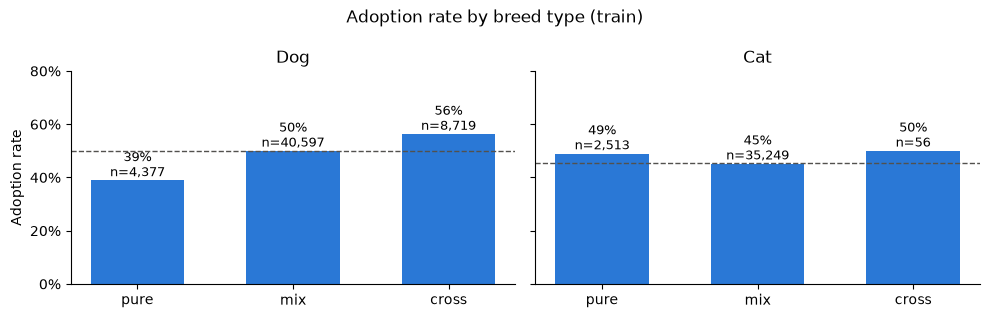

In [19]:
BAR_COLOR = '#2a78d6'
REF_COLOR = '#52514e'

train = df[df['split'] == 'train']

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, animal in zip(axes, ['Dog', 'Cat']):
    subset = train[train['animal_type_intake'] == animal]
    rates = subset.groupby('breed_type')['adopted'].agg(['mean', 'size']).reindex(['pure', 'mix', 'cross'])

    ax.bar(rates.index, rates['mean'], color=BAR_COLOR, width=0.6)
    ax.axhline(subset['adopted'].mean(), color=REF_COLOR, linestyle='--', linewidth=1)
    for x, (rate, n) in enumerate(zip(rates['mean'], rates['size'])):
        ax.annotate(f'{rate:.0%}\nn={n:,}', (x, rate), ha='center', va='bottom', fontsize=9)

    ax.set_title(animal)
    ax.set_ylim(0, 0.8)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_ylabel('Adoption rate')
fig.suptitle('Adoption rate by breed type (train)')
fig.tight_layout()

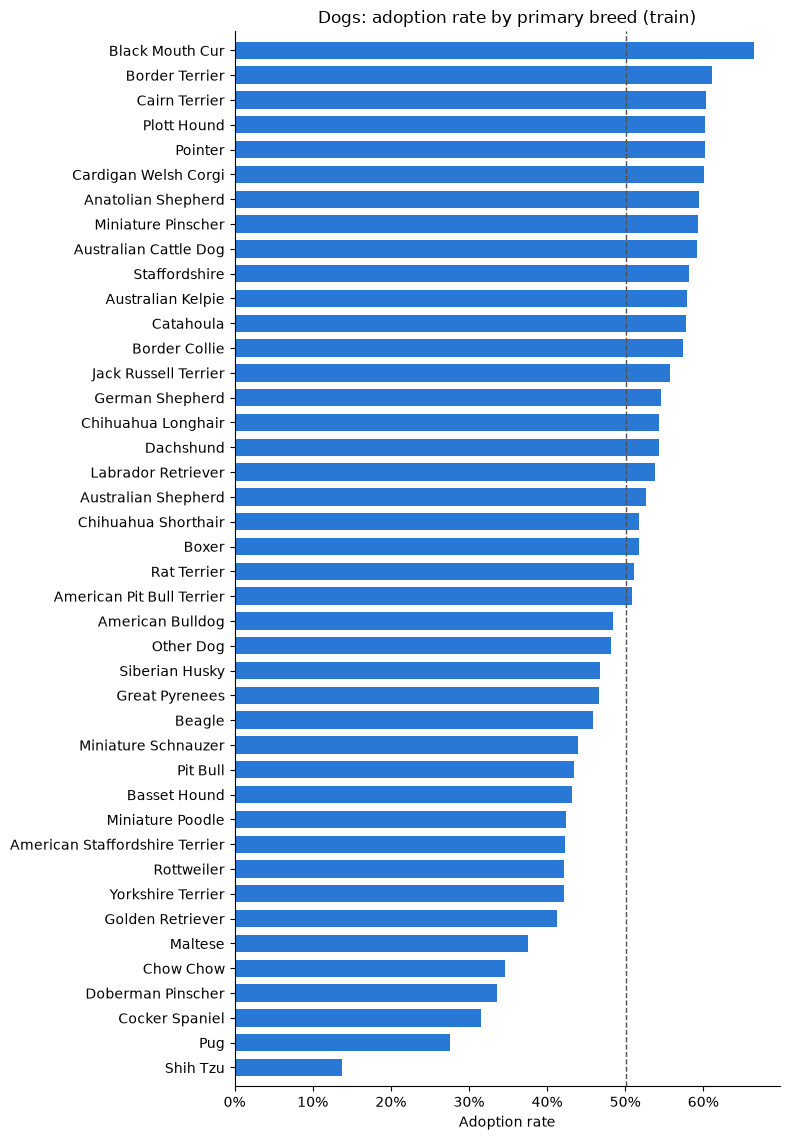

In [20]:
dog_rates = (
    train[train['animal_type_intake'] == 'Dog']
    .groupby('primary_breed_grouped')['adopted']
    .agg(rate='mean', stays='size')
    .sort_values('rate')
)

fig, ax = plt.subplots(figsize=(8, 0.25 * len(dog_rates) + 1))
ax.barh(dog_rates.index, dog_rates['rate'], color=BAR_COLOR, height=0.7)
ax.axvline(train.loc[train['animal_type_intake'] == 'Dog', 'adopted'].mean(),
           color=REF_COLOR, linestyle='--', linewidth=1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.spines[['top', 'right']].set_visible(False)
ax.margins(y=0.01)
ax.set_xlabel('Adoption rate')
ax.set_title('Dogs: adoption rate by primary breed (train)')
fig.tight_layout()

In [21]:
(
    train[train['animal_type_intake'] == 'Cat']
    .groupby('primary_breed_grouped')['adopted']
    .agg(rate='mean', stays='size')
    .sort_values('stays', ascending=False)
    .round(3)
)

,rate,stays
primary_breed_grouped,,
Domestic Shorthair,0.446,30755
Domestic Medium Hair,0.484,3233
Domestic Longhair,0.505,1524
Siamese,0.473,1285
Other Cat,0.543,781
American Shorthair,0.383,240


## Other intake features

Everything here is known the moment the animal arrives:

| Feature | From | Notes |
|---|---|---|
| `age_days` | `age_upon_intake` | "2 years" -> 730. A few negative ages are data-entry errors, clipped to 0 |
| `sex`, `is_fixed` | `sex_upon_intake` | "Neutered Male" -> sex = Male, is_fixed = 1 |
| `color_primary`, `is_multicolor` | `color_intake` | "Brown Tabby/White" -> "Brown Tabby", multicolor |
| `intake_month` | `intake_datetime` | seasonality (kitten season) |
| `prior_stays` | stay history | how many times this animal came in before |

**Name is deliberately excluded.** `name_intake` equals `name_outcome` in 100% of rows, so it's the animal's *final* name,
not the name it had at intake. Shelter-assigned names (starting with `*`) are adopted 72% of the time, likely because
the shelter names animals it puts up for adoption. Using it would leak the outcome.

In [22]:
DAYS_PER_UNIT = {'day': 1, 'week': 7, 'month': 30, 'year': 365}

age_number = df['age_upon_intake'].str.split().str[0].astype(float)
age_unit = df['age_upon_intake'].str.split().str[1].str.rstrip('s')

df = df.assign(
    age_days=(age_number * age_unit.map(DAYS_PER_UNIT)).clip(lower=0),
    sex=df['sex_upon_intake'].fillna('Unknown').str.split().str[-1],
    is_fixed=df['sex_upon_intake'].str.contains('Neutered|Spayed').astype(int),
    color_primary=df['color_intake'].str.split('/').str[0],
    is_multicolor=df['color_intake'].str.contains('/').astype(int),
    intake_month=df['intake_datetime'].dt.month,
    prior_stays=df.groupby('animal_id').cumcount(),  # df is sorted by intake date
)

df[['age_upon_intake', 'age_days', 'sex_upon_intake', 'sex', 'is_fixed',
    'color_intake', 'color_primary', 'is_multicolor', 'prior_stays']].sample(6, random_state=2)

,age_upon_intake,age_days,sex_upon_intake,sex,is_fixed,color_intake,color_primary,is_multicolor,prior_stays
104615,1 week,7.0,Unknown,Unknown,0,Brown Tabby/White,Brown Tabby,1,0
58264,1 year,365.0,Intact Female,Female,0,Brown/Black,Brown,1,0
60775,2 weeks,14.0,Unknown,Unknown,0,Tortie,Tortie,0,0
78485,1 weeks,7.0,Intact Female,Female,0,Blue Tabby/White,Blue Tabby,1,0
87416,4 years,1460.0,Neutered Male,Male,1,Black/White,Black,1,0
138428,2 months,60.0,Intact Male,Male,0,White/Gray,White,1,0


Same rare-category treatment as breed: categories with fewer than `MIN_TRAIN_ROWS` training stays become `Other`.

In [23]:
def group_rare(column, min_rows=MIN_TRAIN_ROWS):
    counts = df.loc[df['split'] == 'train', column].value_counts()
    common = counts[counts >= min_rows].index
    return df[column].where(df[column].isin(common), 'Other')

df['color_primary_grouped'] = group_rare('color_primary')
df['intake_condition_grouped'] = group_rare('intake_condition')

df[['color_primary', 'color_primary_grouped', 'intake_condition', 'intake_condition_grouped']].nunique()

color_primary               59
color_primary_grouped       32
intake_condition            20
intake_condition_grouped     6
dtype: int64

## Feature importance

Before modelling, a quick check of how much each feature tells us about adoption, on the **training split only**:

- **Categorical features**: mutual information with `adopted` (higher = more informative)
- **Numeric features**: correlation with `adopted`

In [24]:
CATEGORICAL = [
    'animal_type_intake',
    'intake_type',
    'intake_condition_grouped',
    'sex',
    'breed_type',
    'primary_breed_grouped',
    'color_primary_grouped',
]
NUMERIC = [
    'age_days',
    'is_fixed',
    'is_multicolor',
    'intake_month',
    'prior_stays',
]
FEATURES = CATEGORICAL + NUMERIC

df_train = df[df['split'] == 'train'].reset_index(drop=True)
df_val = df[df['split'] == 'val'].reset_index(drop=True)
df_test = df[df['split'] == 'test'].reset_index(drop=True)
y_train, y_val, y_test = df_train['adopted'], df_val['adopted'], df_test['adopted']

In [25]:
from sklearn.metrics import mutual_info_score

(
    df_train[CATEGORICAL]
    .apply(lambda col: mutual_info_score(col, y_train))
    .sort_values(ascending=False)
    .round(4)
    .rename('mutual_info')
)

sex                         0.0268
intake_type                 0.0102
intake_condition_grouped    0.0099
primary_breed_grouped       0.0074
color_primary_grouped       0.0023
breed_type                  0.0018
animal_type_intake          0.0011
Name: mutual_info, dtype: float64

In [26]:
df_train[NUMERIC].corrwith(y_train).sort_values(key=abs, ascending=False).round(3).rename('correlation')

age_days        -0.144
is_fixed        -0.066
is_multicolor    0.043
prior_stays      0.015
intake_month    -0.010
Name: correlation, dtype: float64

## Model training

All models share the same input: `DictVectorizer` one-hot encodes the categorical features and passes numeric ones through.
Models are compared on **ROC AUC on the validation split**. AUC is used because the adoption rate drifts upward over
time (48% train -> 56% val -> 64% test), and AUC measures ranking, which isn't affected by that shift.

Four models, each with a small hyperparameter grid:

1. Logistic regression (linear baseline)
2. Decision tree
3. Random forest
4. Gradient boosting (scikit-learn's `HistGradientBoostingClassifier`)

In [27]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score


def to_dicts(frame):
    return frame[FEATURES].to_dict(orient='records')


dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(to_dicts(df_train))
X_val = dv.transform(to_dicts(df_val))
print(f'Feature matrix: {X_train.shape[0]:,} rows x {X_train.shape[1]} columns')


def val_auc(model):
    model.fit(X_train, y_train)
    return roc_auc_score(y_val, model.predict_proba(X_val)[:, 1])

Feature matrix: 91,511 rows x 101 columns


### 1. Logistic regression

Age is heavily skewed (days to 20+ years), so the linear model gets `log1p(age_days)`. Tree models don't need this.
We tune `C` (inverse regularization strength).

In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

age_col = dv.feature_names_.index('age_days')

def log_age(X):
    X = X.copy()
    X[:, age_col] = np.log1p(X[:, age_col])
    return X

lr_results = pd.Series({
    C: val_auc(make_pipeline(
        FunctionTransformer(log_age),
        StandardScaler(),
        LogisticRegression(C=C, max_iter=1000),
    ))
    for C in [0.001, 0.01, 0.1, 1, 10]
}, name='val_auc').rename_axis('C')
lr_results.round(4)

C
0.001     0.6953
0.010     0.6950
0.100     0.6950
1.000     0.6950
10.000    0.6950
Name: val_auc, dtype: float64

### 2. Decision tree

Tune `max_depth` and `min_samples_leaf`.

In [29]:
dt_results = pd.Series({
    (depth, leaf): val_auc(DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, random_state=1))
    for depth in [5, 10, 15, 20]
    for leaf in [10, 50, 200]
}, name='val_auc').rename_axis(['max_depth', 'min_samples_leaf'])
dt_results.unstack().round(4)

min_samples_leaf,10,50,200
max_depth,,,
5,0.7153,0.7153,0.7153
10,0.7231,0.7246,0.7290
15,0.7068,0.7190,0.7287
20,0.6945,0.7160,0.7277


### 3. Random forest

Tune `max_depth` and `min_samples_leaf` with 100 trees.

In [30]:
rf_results = pd.Series({
    (depth, leaf): val_auc(RandomForestClassifier(
        n_estimators=100, max_depth=depth, min_samples_leaf=leaf, n_jobs=-1, random_state=1,
    ))
    for depth in [10, 20]
    for leaf in [5, 20]
}, name='val_auc').rename_axis(['max_depth', 'min_samples_leaf'])
rf_results.unstack().round(4)

min_samples_leaf,5,20
max_depth,,
10,0.7347,0.7331
20,0.7389,0.7372


### 4. Gradient boosting

Tune `learning_rate` and `max_leaf_nodes` (tree complexity). Early stopping picks the number of trees.

In [31]:
gb_results = pd.Series({
    (lr, leaves): val_auc(HistGradientBoostingClassifier(
        learning_rate=lr, max_leaf_nodes=leaves, max_iter=500,
        early_stopping=True, random_state=1,
    ))
    for lr in [0.05, 0.1, 0.2]
    for leaves in [15, 31, 63]
}, name='val_auc').rename_axis(['learning_rate', 'max_leaf_nodes'])
gb_results.unstack().round(4)

max_leaf_nodes,15,31,63
learning_rate,,,
0.05,0.7432,0.7421,0.7390
0.10,0.7427,0.7427,0.7390
0.20,0.7408,0.7406,0.7353


### Model comparison

In [32]:
comparison = pd.DataFrame({
    'model': ['Logistic regression', 'Decision tree', 'Random forest', 'Gradient boosting'],
    'best_params': [
        ', '.join(f'{name}={value}' for name, value in zip(r.index.names, r.idxmax() if r.index.nlevels > 1 else [r.idxmax()]))
        for r in [lr_results, dt_results, rf_results, gb_results]
    ],
    'val_auc': [r.max() for r in [lr_results, dt_results, rf_results, gb_results]],
}).sort_values('val_auc', ascending=False).round(4)
comparison

,model,best_params,val_auc
3,Gradient boosting,"learning_rate=0.05, max_leaf_nodes=15",0.7432
2,Random forest,"max_depth=20, min_samples_leaf=5",0.7389
1,Decision tree,"max_depth=10, min_samples_leaf=200",0.7290
0,Logistic regression,C=0.001,0.6953


### Feature importance of the best model

Permutation importance: shuffle one feature at a time in the validation set and measure how much AUC drops.
Works for any model, and groups each categorical feature's one-hot columns back together.

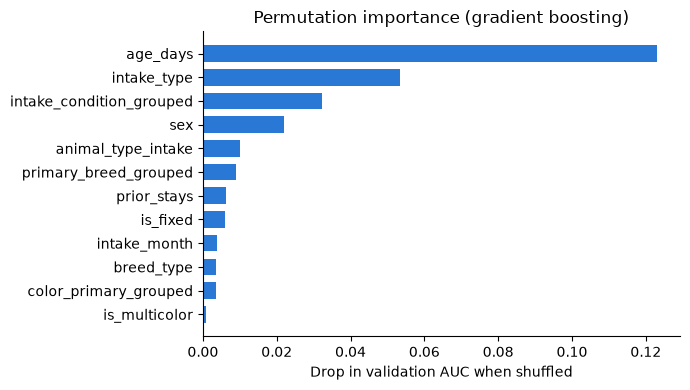

In [33]:
best_lr, best_leaves = gb_results.idxmax()
best_model = HistGradientBoostingClassifier(
    learning_rate=best_lr, max_leaf_nodes=best_leaves, max_iter=500,
    early_stopping=True, random_state=1,
).fit(X_train, y_train)

def auc_on(frame):
    return roc_auc_score(frame['adopted'], best_model.predict_proba(dv.transform(to_dicts(frame)))[:, 1])

rng = np.random.default_rng(1)
baseline = auc_on(df_val)
importance = pd.Series({
    feature: baseline - auc_on(df_val.assign(**{feature: rng.permutation(df_val[feature].values)}))
    for feature in FEATURES
}).sort_values()

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance.index, importance.values, color=BAR_COLOR, height=0.7)
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlabel('Drop in validation AUC when shuffled')
ax.set_title('Permutation importance (gradient boosting)')
fig.tight_layout()

### Final check on the test split

Retrain the chosen model on train + validation, then score the untouched test split (the most recent ~3 years) once.

In [34]:
df_full_train = pd.concat([df_train, df_val])
X_full_train = dv.fit_transform(to_dicts(df_full_train))
X_test = dv.transform(to_dicts(df_test))

final_model = HistGradientBoostingClassifier(
    learning_rate=best_lr, max_leaf_nodes=best_leaves, max_iter=500,
    early_stopping=True, random_state=1,
).fit(X_full_train, df_full_train['adopted'])

print(f"Test AUC: {roc_auc_score(y_test, final_model.predict_proba(X_test)[:, 1]):.4f}")

Test AUC: 0.7743
